## Parashikimi i shitjeve ditore

In [25]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_data, clean_data, add_columns
from src.forecasting import build_daily_series, validate_daily

sales, returns = clean_data(load_data())
sales = add_columns(sales)
returns = add_columns(returns)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Rreshta fillestare: 1,067,371
Dublikate:                                 hequr:    34335 | mbeten: 1,033,036
Anulime (ndahen te returns)                hequr:    19104 | mbeten: 1,013,932
Quantity <= 0                              hequr:     3393 | mbeten: 1,010,539
Price <= 0                                 hequr:     2626 | mbeten: 1,007,913
Kode te cilat nuk jane produkte            hequr:     4699 | mbeten: 1,003,214
Kodet e hequra (top 10):  {'POST': 1851, 'DOT': 1415, 'M': 846, 'C2': 267, 'ADJUST': 36, 'BANK CHARGES': 34, 'DCGS0058': 30, 'gift_0001_20': 26, 'gift_0001_30': 24, 'DCGSSGIRL': 23}
Rreshta te shitjes pas pastrimit: 1,003,214


In [26]:
last = sales["InvoiceDate"].max()
last_day = sales["Date"].max()
print("Fatura e fundit: ", last)
print("Te ardhurat e dites se fundit:", round(sales.loc[sales["Date"] == last_day, "Revenue"].sum()))
print("Mediana e te ardhurave ditore (ditet me shitje):", round(sales.groupby("Date")["Revenue"].sum().median()))

Fatura e fundit:  2011-12-09 12:50:00
Te ardhurat e dites se fundit: 198095
Mediana e te ardhurave ditore (ditet me shitje): 28180


In [27]:
daily = build_daily_series(sales, returns, drop_last_day=True)
validate_daily(daily)
print(daily.shape)
daily.head(10)


Kontrollet e serise ditore: OK
Dite me te ardhura neto negative: 3
(738, 5)


,revenue,orders,refunds,is_open,net_revenue
Date,,,,,
2009-12-01,52429.13,117,-1340.47,True,51088.66
2009-12-02,61873.10,115,-588.92,True,61284.18
2009-12-03,73025.12,124,-5944.86,True,67080.26
2009-12-04,39349.21,88,-386.52,True,38962.69
2009-12-05,9803.05,30,0.00,True,9803.05
2009-12-06,24285.02,74,-296.44,True,23988.58
2009-12-07,42923.68,101,-746.33,True,42177.35
2009-12-08,48694.71,105,-5774.09,True,42920.62
2009-12-09,38851.26,87,-219.54,True,38631.72


In [28]:
print(round(daily["revenue"].sum()), round(sales["Revenue"].sum()))

19444598 19642692


In [29]:
#ditet pa shitje
closed = daily[~daily["is_open"]]
print("Dite kalendarike:", len(daily))
print("Dite me shitje:", int(daily["is_open"].sum()))
print("Dite pa shitje:", len(closed))
print(closed.index.day_name().value_counts())

Dite kalendarike: 738
Dite me shitje: 603
Dite pa shitje: 135
Date
Saturday     104
Monday        11
Friday         7
Sunday         6
Thursday       3
Tuesday        2
Wednesday      2
Name: count, dtype: int64


In [30]:
run_id = daily["is_open"].ne(daily["is_open"].shift()).cumsum()
runs = (daily.reset_index().groupby(run_id.values).agg(
                nga=("Date", "min"),
                deri=("Date", "max"),
                dite=("Date", "size"),
                hapur=("is_open", "first")
            ))
runs[(~runs["hapur"]) & (runs["dite"] >= 3)]

,nga,deri,dite,hapur
6,2009-12-24,2010-01-03,11,False
32,2010-04-02,2010-04-05,4,False
114,2010-12-24,2011-01-03,11,False
146,2011-04-22,2011-04-25,4,False


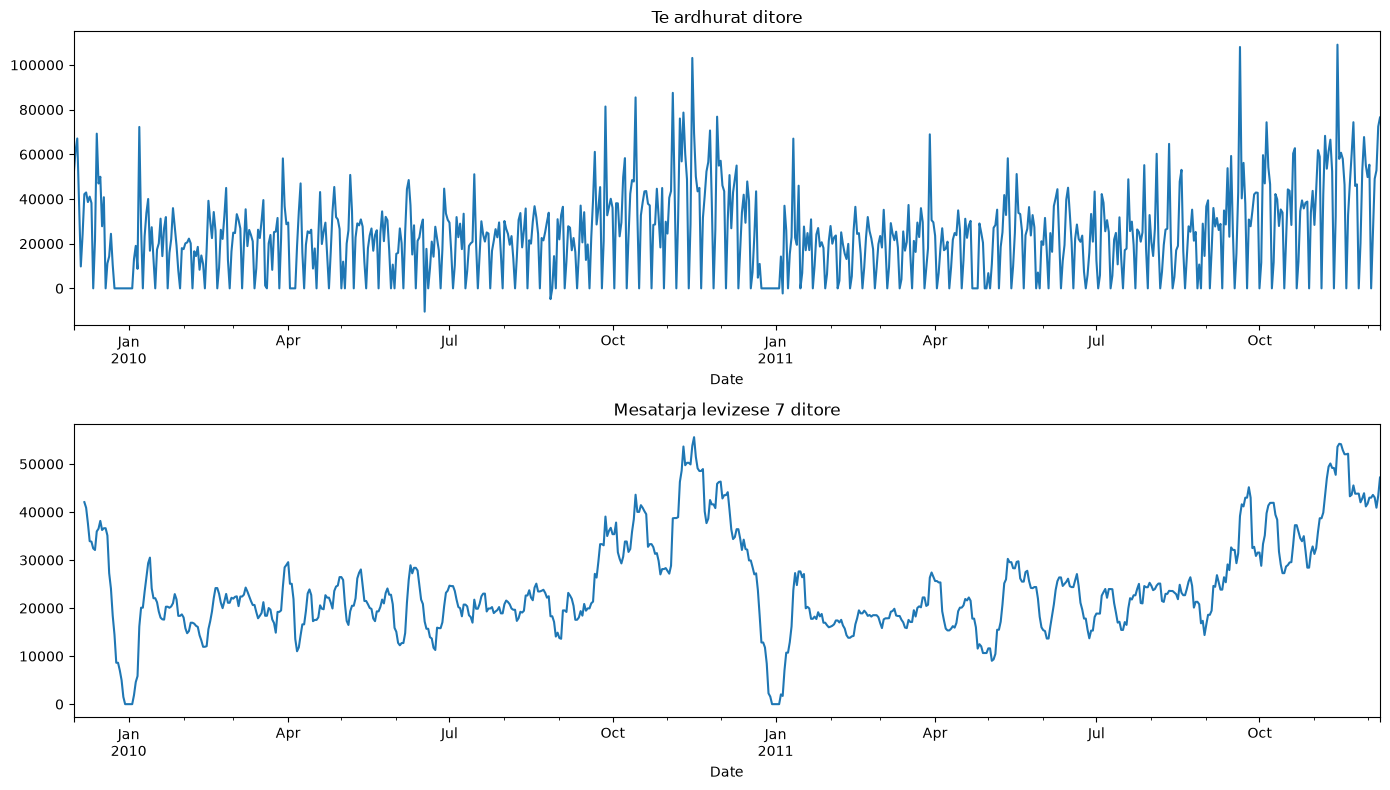

In [31]:
fig, axes = plt.subplots(2, 1 , figsize=(14, 8))
daily["net_revenue"].plot(ax=axes[0], title="Te ardhurat ditore")
daily["net_revenue"].rolling(7).mean().plot(ax=axes[1], title="Mesatarja levizese 7 ditore")
plt.tight_layout()
plt.show()

In [38]:
daily["weekday"] = daily.index.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print(daily.groupby("weekday")["net_revenue"].agg(["mean", "median"]).reindex(order).round(0))

open_days = daily[daily["is_open"]]
print(open_days["net_revenue"].describe().round(0))
open_days["net_revenue"].nlargest(5)

              mean   median
weekday                    
Monday     30017.0  26214.0
Tuesday    33265.0  28677.0
Wednesday  30227.0  27646.0
Thursday   35424.0  31798.0
Friday     26092.0  25116.0
Saturday      93.0      0.0
Sunday     16810.0  16613.0
count       603.0
mean      30102.0
std       16133.0
min      -10426.0
25%       19747.0
50%       26647.0
75%       37579.0
max      109070.0
Name: net_revenue, dtype: float64


Date
2011-11-14    109069.83
2011-09-20    108038.52
2010-11-15    103134.36
2010-11-04     87508.49
2010-10-14     85466.39
Name: net_revenue, dtype: float64

In [33]:
inv = sales.groupby(["Date", "Invoice"])["Revenue"].sum().reset_index()
open_days = daily[daily["is_open"]]

for d in open_days["revenue"].nlargest(6).index:
    day = inv[inv["Date"] == d].sort_values("Revenue", ascending=False)
    top = day.iloc[0]
    share = top["Revenue"] / day["Revenue"].sum() * 100
    print(d.date(), "| dita:", round(day["Revenue"].sum()), "| fatura me e madhe:", top["Invoice"], round(top["Revenue"]), f"({share:.0f}%)")

2011-11-14 | dita: 111349 | fatura me e madhe: 576365 50654 (45%)
2011-09-20 | dita: 108364 | fatura me e madhe: 567423 31698 (29%)
2010-11-15 | dita: 103336 | fatura me e madhe: 533027 49845 (48%)
2010-09-27 | dita: 102425 | fatura me e madhe: 524181 33168 (32%)
2011-01-18 | dita: 94365 | fatura me e madhe: 541431 77184 (82%)
2010-11-04 | dita: 88826 | fatura me e madhe: 530715 17022 (19%)


In [34]:
row = sales[sales["Date"] == "2011-12-09"].nlargest(1, "Revenue").iloc[0]
print(row[["Invoice", "InvoiceDate", "StockCode", "Description", "Quantity", "Price", "Customer ID", "Revenue"]])

returns[(returns["StockCode"] == row["StockCode"]) & (returns["Customer ID"] == row["Customer ID"])][["Invoice", "InvoiceDate", "Quantity", "Revenue"]]

Invoice                             581483
InvoiceDate            2011-12-09 09:15:00
StockCode                            23843
Description    PAPER CRAFT , LITTLE BIRDIE
Quantity                             80995
Price                                 2.08
Customer ID                          16446
Revenue                           168469.6
Name: 1001747, dtype: object


,Invoice,InvoiceDate,Quantity,Revenue
1065883,C581484,2011-12-09 09:27:00,-80995,-168469.6


In [35]:
print("Shitje:", round(sales["Revenue"].sum()), "| Anulime:", round(returns["Revenue"].sum()))
print("Anulimet si % e shitjeve:", round(-returns["Revenue"].sum() / sales["Revenue"].sum() * 100, 1))

Shitje: 19642692 | Anulime: -1462051
Anulimet si % e shitjeve: 7.4


In [36]:
for inv_no in ["581483", "541431"]:
    r = sales[sales["Invoice"] == inv_no].nlargest(1, "Revenue").iloc[0]
    m = returns[(returns["StockCode"] == r["StockCode"])
                & (returns["Customer ID"] == r["Customer ID"])
                & (returns["Quantity"] == -r["Quantity"])]
    print(inv_no, "|", r["InvoiceDate"], "| sasia", r["Quantity"], "| anulimi:", m[["Invoice", "InvoiceDate"]].to_dict("records"))

581483 | 2011-12-09 09:15:00 | sasia 80995 | anulimi: [{'Invoice': 'C581484', 'InvoiceDate': Timestamp('2011-12-09 09:27:00')}]
541431 | 2011-01-18 10:01:00 | sasia 74215 | anulimi: [{'Invoice': 'C541433', 'InvoiceDate': Timestamp('2011-01-18 10:17:00')}]


In [37]:
cmp = daily.loc[daily["is_open"], ["revenue", "refunds", "net_revenue"]]
cmp.sort_values("revenue", ascending=False).head(8).round(0)

,revenue,refunds,net_revenue
Date,,,
2011-11-14,111349.0,-2279.0,109070.0
2011-09-20,108364.0,-326.0,108039.0
2010-11-15,103336.0,-202.0,103134.0
2010-09-27,102425.0,-21034.0,81391.0
2011-01-18,94365.0,-77297.0,17067.0
2010-11-04,88826.0,-1318.0,87508.0
2010-10-14,86915.0,-1449.0,85466.0
2011-11-07,84150.0,-15881.0,68269.0


## Seria e shitjeve ditore

**Si u nderte**
- Seria ditore ka nje rresht per cdo dite kalendarike, nga 2009-12-01 deri 2011-12-08: 738 dite, nga te cilat 603 kane shitje dhe 135 jane pa shitje (18.3%).
- Per cdo dite ruhen: te ardhurat bruto te shitjeve (revenue), anulimet e dites (refunds, negative), te ardhurat neto (net_revenue = revenue + refunds), numri i faturave (orders) dhe nese ka pasur shitje (is_open).

**Problemi i porosive gjigante qe anulohen**
- Fatura 581483 (2011-12-09, ora 09:15) kishte 80,995 cope te nje produkti (PAPER CRAFT , LITTLE BIRDIE) me vlere 168,470 £, pra 85% e te ardhurave te asaj dite. Fatura C581484 e anuloi te njejten sasi 12 minuta me vone.
- Fatura 541431 (2011-01-18, ora 10:01) kishte 74,215 cope dhe peshonte 82% te te ardhurave te dites. Fatura C541433 e anuloi 16 minuta me vone.
- Mediana e sasise per rresht eshte 3 dhe 99.9% e rreshtave jane nen 500 cope, ndaj keto dy porosi jane me shume se 140 here mbi kete prag. Me shume gjase jane gabime regjistrimi qe u korrigjuan menjehere.
- Meqe anulimet ishin ndare te returns, keto porosi mbeten te shitjet dhe i fryne te ardhurat bruto te dites. Dita 2011-01-18 ka vetem 17,067 £ neto ne vend te 94,365 £ bruto.
- Anulimet gjithsej jane 1,462,051 £ kundrejt 19,642,692 £ shitje, pra 7.4% e vleres se shitjeve.
- Vendim: variabla qe do te parashikohet eshte net_revenue (shitje minus anulime te regjistruara ne te njejten dite). Keshtu porosite e anuluara menjehere neutralizohen vete, pa heqje me dore te diteve te vecanta.

**Bruto kundrejt neto per ditet me te larta**

| Data | Bruto (£) | Anulime (£) | Neto (£) |
|---|---|---|---|
| 2011-11-14 | 111,349 | -2,279 | 109,070 |
| 2011-09-20 | 108,364 | -326 | 108,039 |
| 2010-11-15 | 103,336 | -202 | 103,134 |
| 2010-09-27 | 102,425 | -21,034 | 81,391 |
| 2011-01-18 | 94,365 | -77,297 | 17,067 |
| 2010-11-04 | 88,826 | -1,318 | 87,508 |
| 2010-10-14 | 86,915 | -1,449 | 85,466 |
| 2011-11-07 | 84,150 | -15,881 | 68,269 |

- Shumica e diteve kane anulime shume te vogla, por disa kane ndikim te madh: 2011-01-18 humbet 82% te vleres, 2010-09-27 humbet 20.5% dhe 2011-11-07 humbet 18.9%.
- Kufizim: anulimet regjistrohen ne diten kur behen, jo ne diten e shitjes origjinale. Kur nje porosi anulohet disa dite me vone, shitja mbetet ne diten e saj dhe anulimi zbritet ne diten tjeter. Dite me te ardhura neto negative: ... .

**Dita e fundit**
- Dita 2011-12-09 u hoq nga seria. Fatura e fundit eshte ne ora 12:50, pra dita nuk ka mbaruar dhe nuk krahasohet me ditet e plota. Edhe pas anulimit te porosise gjigante, vlera e mbetur (rreth 29,600 £) eshte per vetem gjysmen e dites.

**Ditet pa shitje (135 nga 738, 18.3%)**
- Shumica jane te Shtunat: 104 nga 105 te Shtuna nuk kane shitje. Pra dyqani praktikisht nuk shet te Shtunave.
- Ditet pa shitje sipas dites se javes: e Shtune 104, e Hene 11, e Premte 7, e Diel 6, e Enjte 3, e Marte 2, e Merkure 2.
- Ka kater pushime te gjata: 2009-12-24 deri 2010-01-03 (11 dite), 2010-04-02 deri 2010-04-05 (4 dite), 2010-12-24 deri 2011-01-03 (11 dite) dhe 2011-04-22 deri 2011-04-25 (4 dite). Sipas datave, jane pushimet e Krishtlindjeve dhe te Pashkeve.
- Vendim: ditet pa shitje marrin revenue = 0, refunds = 0 dhe is_open = False, qe kalendari te mbetet i plote dhe lag_7 te jete gjithmone e njejta dite e javes.

**Te ardhurat neto sipas dites se javes** (mesatare dhe mediane, ne te gjitha ditet kalendarike)

| Dita | Mesatarja (£) | Mediana (£) |
|---|---|---|
| E Hene | 30,017 | 26,214 |
| E Marte | 33,265 | 28,677 |
| E Merkure | 30,227 | 27,646 |
| E Enjte | 35,424 | 31,798 |
| E Premte | 26,092 | 25,116 |
| E Shtune | 93 | 0 |
| E Diel | 16,810 | 16,613 |

- E Shtuna eshte praktikisht e mbyllur dhe e Diela shet rreth 47% te asaj qe shet e Enjtja (mesatare 16,810 £ kundrejt 35,424 £).
- Dita me e forte eshte e Enjtja (mesatare 35,424 £, mediane 31,798 £), e ndjekur nga e Marta (33,265 £). E Premtja eshte dita me e dobet e diteve te punes (mesatare 26,092 £, mediane 25,116 £).

**Te ardhurat neto ditore (ditet me shitje)**
- Ka 603 dite me shitje. Mediana eshte 26,647 £, mesatarja 30,102 £ dhe devijimi standard 16,133 £. Mesatarja eshte mbi median, pra shperndarja ka bisht te gjate djathtas (pak dite me shume shitje).
- Maksimumi eshte 109,070 £ (2011-11-14) dhe minimumi -10,426 £ (dite ku anulimet kalojne shitjet).
- Pese ditet me te larta jane 2011-11-14 (109,070 £), 2011-09-20 (108,039 £), 2010-11-15 (103,134 £), 2010-11-04 (87,508 £) dhe 2010-10-14 (85,466 £). Te gjitha bien ne periudhen shtator-nentor te dy viteve, pra ka nje kulm sezonal ne vjeshte.
- Mesatarja levizese 7-ditore tregon rritje drejt vjeshtes (shtator-nentor) dhe renie te forte ne fund te dhjetorit dhe fillim te janarit, gjate pushimit te fundvitit.

**Kufizime**
- Kemi vetem dy vjet te dhena, pra modeli ka vetem dy shembuj te sezonit te fundvitit per te mesuar sezonalitetin.
- Neto nuk e zgjidh plotesisht problemin e anulimeve qe vijne ditet pas shitjes, dhe mund te ekzistojne edhe porosi te tjera te medha jo te anuluara qe jane te vertetat.
- Pushimet e papritura nuk mund te parashikohen nga asnje model.